## Load the dataset

In [49]:
import pandas as pd
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import shap
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier


In [2]:

# Load the credit card default dataset
file_path = "Downloads/default of credit card clients.csv"

df = pd.read_csv(file_path)
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## Inspect the dataset structure

In [3]:

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())


Dataset shape: (5645, 25)

Column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


##  Data types and missing values

In [4]:

# Display the data type of each column
print("DATA TYPES")
print(df.dtypes)

# Count missing values in each column
print("\nMISSING VALUES")
print(df.isnull().sum())

# Calculate the total number of missing values
print("\nTotal missing values:", df.isnull().sum().sum())


DATA TYPES
ID                            int64
LIMIT_BAL                     int64
SEX                           int64
EDUCATION                     int64
MARRIAGE                      int64
AGE                           int64
PAY_0                         int64
PAY_2                         int64
PAY_3                         int64
PAY_4                         int64
PAY_5                         int64
PAY_6                         int64
BILL_AMT1                     int64
BILL_AMT2                     int64
BILL_AMT3                     int64
BILL_AMT4                     int64
BILL_AMT5                     int64
BILL_AMT6                     int64
PAY_AMT1                      int64
PAY_AMT2                      int64
PAY_AMT3                      int64
PAY_AMT4                      int64
PAY_AMT5                      int64
PAY_AMT6                      int64
default payment next month    int64
dtype: object

MISSING VALUES
ID                            0
LIMIT_BAL                  

## Analyze the target variable

Target variable counts:
default payment next month
0    4408
1    1237
Name: count, dtype: int64

Target variable percentages:
default payment next month
0    78.09
1    21.91
Name: proportion, dtype: float64


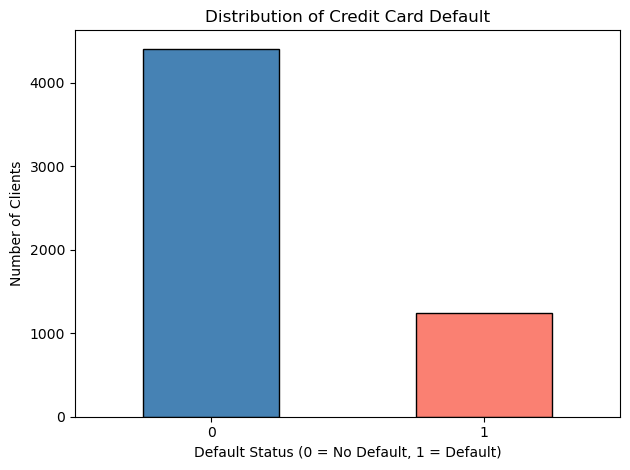

In [6]:

# Define the target column
target = "default payment next month"

# Count the observations in each target class
print("Target variable counts:")
print(df[target].value_counts().sort_index())

# Calculate the percentage of each class
print("\nTarget variable percentages:")
print((df[target].value_counts(normalize=True).sort_index() * 100).round(2))

# Visualize the target distribution
import matplotlib.pyplot as plt

df[target].value_counts().sort_index().plot(
    kind="bar",
    color=["steelblue", "salmon"],
    edgecolor="black"
)

plt.title("Distribution of Credit Card Default")
plt.xlabel("Default Status (0 = No Default, 1 = Default)")
plt.ylabel("Number of Clients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [7]:

# Display descriptive statistics for all numerical columns
df.describe().T


,count,mean,std,min,25%,50%,75%,max
ID,5645.0,2823.000000,1629.715466,1.0,1412.0,2823.0,4234.0,5645.0
LIMIT_BAL,5645.0,165251.727192,130321.485017,10000.0,50000.0,140000.0,230000.0,1000000.0
SEX,5645.0,1.574845,0.494410,1.0,1.0,2.0,2.0,2.0
EDUCATION,5645.0,1.825686,0.770017,0.0,1.0,2.0,2.0,6.0
MARRIAGE,5645.0,1.567582,0.525985,0.0,1.0,2.0,2.0,3.0
AGE,5645.0,35.439150,9.307339,21.0,28.0,34.0,41.0,75.0
PAY_0,5645.0,0.001240,1.119933,-2.0,-1.0,0.0,0.0,8.0
PAY_2,5645.0,-0.150576,1.193831,-2.0,-1.0,0.0,0.0,7.0
PAY_3,5645.0,-0.159965,1.212426,-2.0,-1.0,0.0,0.0,7.0
PAY_4,5645.0,-0.244287,1.136356,-2.0,-1.0,0.0,0.0,7.0


## Separate features (X) and target (y)

In [10]:

# Remove the ID and target columns from the input features
X = df.drop(columns=["ID", target])

# Store the target variable separately
y = df[target]

# Display the dimensions
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

# Display the feature names
print("\nInput features:")
print(X.columns.tolist())


Feature matrix shape: (5645, 23)
Target vector shape: (5645,)

Input features:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


## Split into training (70%) and testing (30%)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.30,random_state=42,stratify=y)

# Display the dimensions of each split
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)


Training features: (3951, 23)
Testing features: (1694, 23)


## Calculate the correlation matrix

In [17]:

# Calculate Pearson correlation between training features
correlation_matrix = X_train.corr(method="pearson")

# Display the correlation matrix
correlation_matrix.round(2)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
LIMIT_BAL,1.00,0.03,-0.23,-0.15,0.17,-0.22,-0.27,-0.26,-0.25,-0.23,...,0.32,0.32,0.31,0.30,0.22,0.24,0.22,0.20,0.22,0.23
SEX,0.03,1.00,0.01,-0.03,-0.11,-0.06,-0.07,-0.07,-0.06,-0.06,...,-0.04,-0.04,-0.03,-0.04,0.01,0.00,-0.00,0.00,-0.02,-0.00
EDUCATION,-0.23,0.01,1.00,-0.14,0.17,0.12,0.15,0.12,0.12,0.12,...,0.00,-0.01,-0.01,-0.01,-0.05,-0.07,-0.05,-0.05,-0.06,-0.03
MARRIAGE,-0.15,-0.03,-0.14,1.00,-0.39,0.01,0.02,0.04,0.05,0.04,...,-0.07,-0.06,-0.06,-0.07,-0.04,-0.03,-0.02,-0.00,-0.05,-0.01
AGE,0.17,-0.11,0.17,-0.39,1.00,-0.04,-0.05,-0.05,-0.05,-0.03,...,0.08,0.07,0.07,0.08,0.03,0.05,0.04,0.02,0.05,0.04
PAY_0,-0.22,-0.06,0.12,0.01,-0.04,1.00,0.65,0.56,0.52,0.48,...,0.19,0.19,0.20,0.19,-0.10,-0.09,-0.06,-0.07,-0.04,-0.07
PAY_2,-0.27,-0.07,0.15,0.02,-0.05,0.65,1.00,0.78,0.69,0.65,...,0.26,0.26,0.26,0.25,-0.08,-0.08,-0.04,-0.05,-0.03,-0.04
PAY_3,-0.26,-0.07,0.12,0.04,-0.05,0.56,0.78,1.00,0.80,0.72,...,0.23,0.24,0.24,0.23,-0.01,-0.09,-0.03,-0.05,-0.02,-0.04
PAY_4,-0.25,-0.06,0.12,0.05,-0.05,0.52,0.69,0.80,1.00,0.84,...,0.26,0.27,0.27,0.26,-0.01,-0.00,-0.05,-0.04,-0.02,-0.02
PAY_5,-0.23,-0.06,0.12,0.04,-0.03,0.48,0.65,0.72,0.84,1.00,...,0.26,0.29,0.29,0.28,-0.02,-0.00,0.02,-0.06,-0.02,-0.02


## Visualize the correlation matrix

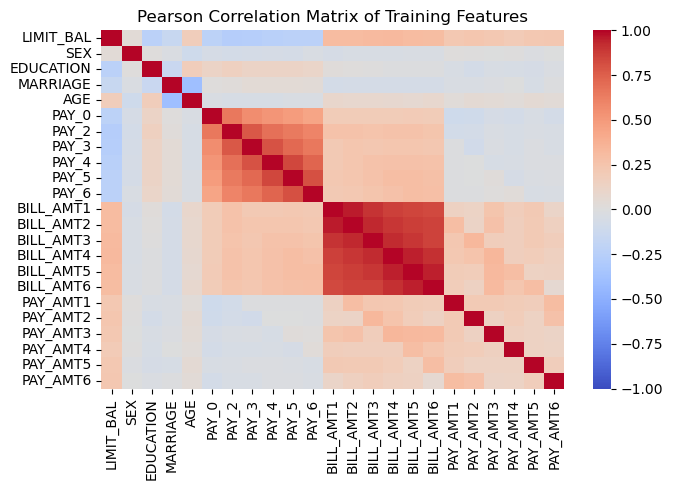

In [57]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Matrix of Training Features")
plt.tight_layout()
plt.show()


## Find highly correlated feature pairs

In [19]:
# Set the correlation threshold
threshold = 0.85

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Extract feature pairs with absolute correlation > 0.85
high_corr_pairs = []

for column in upper_triangle.columns:
    for row in upper_triangle.index:
        corr_value = upper_triangle.loc[row, column]

        if pd.notna(corr_value) and abs(corr_value) > threshold:
            high_corr_pairs.append(
                (row, column, corr_value)
            )

# Display the results
print("Highly correlated feature pairs:")
print("")

if high_corr_pairs:
    for feature1, feature2, corr_value in high_corr_pairs:
        print(
            f"{feature1} <-> {feature2}: "
            f"correlation = {corr_value:.3f}"
        )
else:
    print("No feature pairs exceed the threshold of 0.8.")

print("\nNumber of highly correlated pairs:", len(high_corr_pairs))


Highly correlated feature pairs:

BILL_AMT1 <-> BILL_AMT2: correlation = 0.953
BILL_AMT1 <-> BILL_AMT3: correlation = 0.900
BILL_AMT2 <-> BILL_AMT3: correlation = 0.931
BILL_AMT1 <-> BILL_AMT4: correlation = 0.866
BILL_AMT2 <-> BILL_AMT4: correlation = 0.897
BILL_AMT3 <-> BILL_AMT4: correlation = 0.926
BILL_AMT2 <-> BILL_AMT5: correlation = 0.872
BILL_AMT3 <-> BILL_AMT5: correlation = 0.892
BILL_AMT4 <-> BILL_AMT5: correlation = 0.948
BILL_AMT2 <-> BILL_AMT6: correlation = 0.852
BILL_AMT3 <-> BILL_AMT6: correlation = 0.857
BILL_AMT4 <-> BILL_AMT6: correlation = 0.910
BILL_AMT5 <-> BILL_AMT6: correlation = 0.950

Number of highly correlated pairs: 13


## Calculate individual-feature ROC-AUC

In [20]:
# Calculate ROC-AUC for each feature using training data only
feature_auc = {}

for feature in X_train.columns:
    auc = roc_auc_score(y_train, X_train[feature])

    # AUC below 0.5 means the feature's direction is reversed.
    # Use the larger of AUC and 1 - AUC to measure discrimination.
    feature_auc[feature] = max(auc, 1 - auc)

# Display predictive power for each correlated pair
for feature1, feature2, corr_value in high_corr_pairs:
    print(f"\nCorrelated pair: {feature1} and {feature2}")
    print(f"Correlation: {corr_value:.3f}")
    print(f"{feature1} ROC-AUC: {feature_auc[feature1]:.4f}")
    print(f"{feature2} ROC-AUC: {feature_auc[feature2]:.4f}")

    if feature_auc[feature1] >= feature_auc[feature2]:
        print(f"Retain: {feature1}")
        print(f"Candidate to drop: {feature2}")
    else:
        print(f"Retain: {feature2}")
        print(f"Candidate to drop: {feature1}")



Correlated pair: BILL_AMT1 and BILL_AMT2
Correlation: 0.953
BILL_AMT1 ROC-AUC: 0.5217
BILL_AMT2 ROC-AUC: 0.5144
Retain: BILL_AMT1
Candidate to drop: BILL_AMT2

Correlated pair: BILL_AMT1 and BILL_AMT3
Correlation: 0.900
BILL_AMT1 ROC-AUC: 0.5217
BILL_AMT3 ROC-AUC: 0.5132
Retain: BILL_AMT1
Candidate to drop: BILL_AMT3

Correlated pair: BILL_AMT2 and BILL_AMT3
Correlation: 0.931
BILL_AMT2 ROC-AUC: 0.5144
BILL_AMT3 ROC-AUC: 0.5132
Retain: BILL_AMT2
Candidate to drop: BILL_AMT3

Correlated pair: BILL_AMT1 and BILL_AMT4
Correlation: 0.866
BILL_AMT1 ROC-AUC: 0.5217
BILL_AMT4 ROC-AUC: 0.5057
Retain: BILL_AMT1
Candidate to drop: BILL_AMT4

Correlated pair: BILL_AMT2 and BILL_AMT4
Correlation: 0.897
BILL_AMT2 ROC-AUC: 0.5144
BILL_AMT4 ROC-AUC: 0.5057
Retain: BILL_AMT2
Candidate to drop: BILL_AMT4

Correlated pair: BILL_AMT3 and BILL_AMT4
Correlation: 0.926
BILL_AMT3 ROC-AUC: 0.5132
BILL_AMT4 ROC-AUC: 0.5057
Retain: BILL_AMT3
Candidate to drop: BILL_AMT4

Correlated pair: BILL_AMT2 and BILL_AMT

## Remove redundant features

In [21]:

# Start with an empty set of features to remove
features_to_drop = set()

# Compare predictive power for each highly correlated pair
for feature1, feature2, corr_value in high_corr_pairs:

    if feature_auc[feature1] >= feature_auc[feature2]:
        features_to_drop.add(feature2)
    else:
        features_to_drop.add(feature1)

# Apply the correlation filter to the training and test sets
X_train_A = X_train.drop(columns=list(features_to_drop))
X_test_A = X_test.drop(columns=list(features_to_drop))

# Display the results
print("Features before correlation filtering:", X_train.shape[1])
print("Features removed:", len(features_to_drop))
print("Features after correlation filtering:", X_train_A.shape[1])

print("\nFeatures removed:")
print(sorted(features_to_drop))

print("\nFeatures remaining:")
print(X_train_A.columns.tolist())


Features before correlation filtering: 23
Features removed: 5
Features after correlation filtering: 18

Features removed:
['BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']

Features remaining:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


## Prepare the training data

In [22]:
# Combine training features and target for IV calculation
train_iv_data = X_train_A.copy()
train_iv_data["default payment next month"] = y_train

print("Training data shape for IV analysis:", train_iv_data.shape)
print("\nFirst five rows:")
display(train_iv_data.head())


Training data shape for IV analysis: (3951, 19)

First five rows:


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1482,340000,2,2,1,36,0,0,0,0,0,0,167474,7106,4435,4091,3548,4535,4127,0
3760,80000,1,4,2,27,-2,-2,-2,-2,-2,-2,46089,4840,0,0,0,0,0,0
3419,360000,1,1,1,46,-1,-1,-1,-1,0,0,2171,1068,91679,45086,2223,2091,9890,0
1299,70000,1,2,1,37,-1,2,0,0,-1,-1,10323,0,3559,189,7086,3370,0,1
1491,160000,1,3,2,52,0,0,0,0,0,0,155684,6525,6649,2724,2503,2310,2200,0


## Calculate and display IV

In [58]:
import scorecardpy as sc
# Calculate Weight of Evidence (WoE) bins using training data
bins = sc.woebin(
    train_iv_data,
    y="default payment next month",
    x=X_train_A.columns.tolist(),
    positive="1",
    print_info=False
)

# Calculate Information Value for each feature
iv_results = []

for feature, bin_table in bins.items():
    iv = bin_table["total_iv"].iloc[0]

    iv_results.append({
        "Feature": feature,
        "IV": iv
    })

# Convert results to a DataFrame and sort by IV
iv_df = pd.DataFrame(iv_results)
iv_df = iv_df.sort_values("IV", ascending=True).reset_index(drop=True)


C:\Users\user\anaconda3\Lib\site-packages\scorecardpy\condition_fun.py:40: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
C:\Users\user\anaconda3\Lib\site-packages\scorecardpy\condition_fun.py:40: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
C:\Users\user\anaconda3\Lib\site-packages\scorecardpy\woebin.py:320: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observe

In [28]:
print("Information Value for each feature:")
display(iv_df)

Information Value for each feature:


,Feature,IV
0,SEX,0.002852
1,MARRIAGE,0.009568
2,EDUCATION,0.013171
3,BILL_AMT1,0.024193
4,AGE,0.040316
5,LIMIT_BAL,0.081664
6,PAY_AMT4,0.096380
7,PAY_AMT5,0.098083
8,PAY_AMT3,0.104177
9,PAY_AMT6,0.117781


#### Remove features with Information Value (IV) ≤ 0

In [31]:

# Identify features with Information Value <= 0
features_to_drop_iv = iv_df.loc[iv_df["IV"] <= 0, "Feature"].tolist()

# Remove those features from both datasets
X_train_B = X_train_A.drop(columns=features_to_drop_iv)
X_test_B = X_test_A.drop(columns=features_to_drop_iv)

# Display the results
print("Features before IV filtering:", X_train_A.shape[1])
print("Features removed (IV <= 0.0):", len(features_to_drop_iv))
print("Features after IV filtering:", X_train_B.shape[1])


Features before IV filtering: 18
Features removed (IV <= 0.0): 0
Features after IV filtering: 18


In [59]:
# Check the shapes of the training data and target

print("X_train_B shape:", X_train_B.shape)
print("X_test_B shape:", X_test_B.shape)

X_train_B shape: (3951, 18)
X_test_B shape: (1694, 18)


## Train the LightGBM model

In [34]:

# Create the LightGBM model
lgb_model_C = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=-1,
    random_state=42,
    verbosity=-1
)

# Train using only the training data
lgb_model_C.fit(X_train_B, y_train)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,200
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [35]:
print("LightGBM model trained successfully!")
print("Number of training features:", X_train_B.shape[1])

LightGBM model trained successfully!
Number of training features: 18


## Calculate SHAP values

In [38]:

# Create a SHAP explainer for the trained model
explainer = shap.TreeExplainer(lgb_model_C)

# Calculate SHAP values using training data only
shap_values = explainer.shap_values(X_train_B)

# Handle binary classification output across SHAP versions
if isinstance(shap_values, list):
    shap_values_positive = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_values_positive = shap_values[:, :, 1]
else:
    shap_values_positive = shap_values

# Calculate mean absolute SHAP value for each feature
mean_abs_shap = np.abs(shap_values_positive).mean(axis=0)

# Create a feature importance table
shap_importance_df = pd.DataFrame({
    "Feature": X_train_B.columns,
    "Mean_Absolute_SHAP": mean_abs_shap
})

# Sort from most to least important
shap_importance_df = shap_importance_df.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("SHAP calculation completed!")
print(shap_importance_df)

SHAP calculation completed!
      Feature  Mean_Absolute_SHAP
0       PAY_0            0.563623
1    PAY_AMT1            0.247211
2    PAY_AMT2            0.243835
3   BILL_AMT1            0.217602
4    PAY_AMT3            0.172149
5    PAY_AMT6            0.157264
6   LIMIT_BAL            0.155589
7    PAY_AMT5            0.153279
8    PAY_AMT4            0.130777
9         AGE            0.106614
10      PAY_3            0.076908
11   MARRIAGE            0.070384
12      PAY_4            0.057404
13      PAY_5            0.052609
14      PAY_6            0.050652
15      PAY_2            0.049320
16        SEX            0.029184
17  EDUCATION            0.025702


C:\Users\user\anaconda3\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


## Select the top 15 features

In [39]:
# Select the 15 most important features

top_15_features = shap_importance_df.head(15)["Feature"].tolist()

# Create the final training and testing datasets
X_train_C = X_train_B[top_15_features].copy()
X_test_C = X_test_B[top_15_features].copy()

print("Features before SHAP selection:", X_train_B.shape[1])
print("Features selected:", len(top_15_features))
print("Features after SHAP selection:", X_train_C.shape[1])

print("\nSelected 15 features:")
print(top_15_features)

Features before SHAP selection: 18
Features selected: 15
Features after SHAP selection: 15

Selected 15 features:
['PAY_0', 'PAY_AMT1', 'PAY_AMT2', 'BILL_AMT1', 'PAY_AMT3', 'PAY_AMT6', 'LIMIT_BAL', 'PAY_AMT5', 'PAY_AMT4', 'AGE', 'PAY_3', 'MARRIAGE', 'PAY_4', 'PAY_5', 'PAY_6']


## Train and evaluate LightGBM at all four stages

In [40]:
# Step 4.2: Evaluate LightGBM at each feature-selection stage

stages = {
    "Original (23 features)": (X_train, X_test),
    "After Step A (Correlation)": (X_train_A, X_test_A),
    "After Step B (IV Filter)": (X_train_B, X_test_B),
    "After Step C (SHAP Top 15)": (X_train_C, X_test_C)
}

results = []

for stage_name, (Xtr, Xte) in stages.items():

    # Create a fresh LightGBM model for each stage
    model = lgb.LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42,
        verbosity=-1
    )

    # Train using training data only
    model.fit(Xtr, y_train)

    # Predict probabilities for AUC calculation
    train_prob = model.predict_proba(Xtr)[:, 1]
    test_prob = model.predict_proba(Xte)[:, 1]

    # Calculate Train and Test AUC
    train_auc = roc_auc_score(y_train, train_prob)
    test_auc = roc_auc_score(y_test, test_prob)

    # Save results
    results.append({
        "Stage": stage_name,
        "Number of Features": Xtr.shape[1],
        "Train AUC": train_auc,
        "Test AUC": test_auc
    })

# Display the comparison table
stage_results_df = pd.DataFrame(results)

print("LightGBM Performance at Each Stage:")
display(stage_results_df.round(4))

LightGBM Performance at Each Stage:


,Stage,Number of Features,Train AUC,Test AUC
0,Original (23 features),23,0.9866,0.7088
1,After Step A (Correlation),18,0.9825,0.7127
2,After Step B (IV Filter),18,0.9825,0.7127
3,After Step C (SHAP Top 15),15,0.9801,0.7154


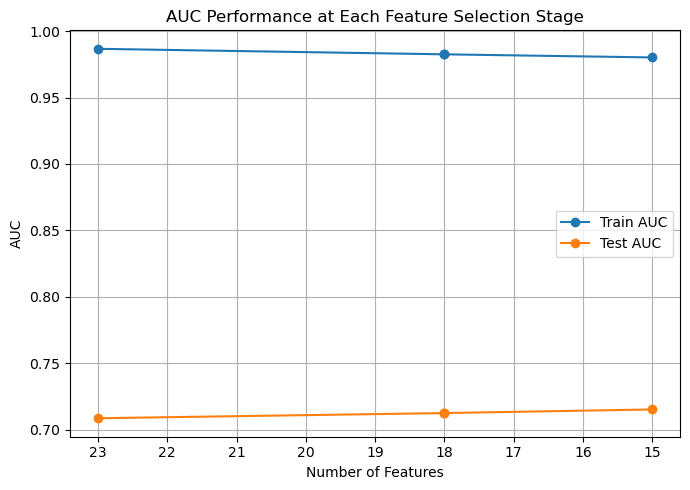

In [47]:
# Number of features at each stage
features = [23, 18, 18, 15]

# AUC values from your stage_results_df table
train_auc = stage_results_df["Train AUC"].tolist()
test_auc = stage_results_df["Test AUC"].tolist()

# Plot Train and Test AUC
plt.figure(figsize=(7, 5))

plt.plot(
    features, train_auc,
    marker='o', label='Train AUC'
)

plt.plot(
    features, test_auc,
    marker='o', label='Test AUC'
)

plt.xlabel("Number of Features")
plt.ylabel("AUC")
plt.title("AUC Performance at Each Feature Selection Stage")
plt.legend()
plt.grid(True)
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()


## Define all six models and their hyperparameters

In [50]:

# Logistic Regression pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# Define the six models and their parameter grids
models = {
    "Logistic Regression": (
        logistic_model,
        {"model__C": [0.1, 1, 10]}
    ),

    "LightGBM": (
        LGBMClassifier(verbosity=-1, random_state=42),
        {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1]
        }
    ),

    "CatBoost": (
        CatBoostClassifier(
            verbose=0,
            random_seed=42,
            allow_writing_files=False,
            thread_count=1
        ),
        {
            "iterations": [100, 200],
            "learning_rate": [0.05, 0.1]
        }
    ),

    "XGBoost": (
        XGBClassifier(
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        ),
        {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1]
        }
    ),

    "AdaBoost": (
        AdaBoostClassifier(random_state=42),
        {
            "n_estimators": [50, 100],
            "learning_rate": [0.05, 0.1]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=1),
        {
            "n_estimators": [100, 200],
            "max_depth": [5, 10]
        }
    )
}

print("Number of models:", len(models))
print("\nModels available for tuning:")
for name in models:
    print("-", name)


Number of models: 6

Models available for tuning:
- Logistic Regression
- LightGBM
- CatBoost
- XGBoost
- AdaBoost
- Random Forest


## Tune all models using GridSearchCV

In [51]:

# Step 6: Hyperparameter tuning for all six models

from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_models = {}
tuning_results = []

for name, (model, param_grid) in models.items():

    print(f"\nTuning {name}...")

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=0
    )

    # Use training data only
    grid.fit(X_train_C, y_train)

    # Save the best fitted model
    best_models[name] = grid.best_estimator_

    # Save tuning results
    tuning_results.append({
        "Model": name,
        "Best CV AUC": grid.best_score_,
        "Best Parameters": grid.best_params_
    })

    print("Best CV AUC:", round(grid.best_score_, 4))
    print("Best parameters:", grid.best_params_)

tuning_results_df = pd.DataFrame(tuning_results)

print("\nHyperparameter Tuning Summary:")
display(tuning_results_df.round(4))



Tuning Logistic Regression...
Best CV AUC: 0.6925
Best parameters: {'model__C': 0.1}

Tuning LightGBM...
Best CV AUC: 0.7422
Best parameters: {'learning_rate': 0.05, 'n_estimators': 100}

Tuning CatBoost...
Best CV AUC: 0.7603
Best parameters: {'iterations': 100, 'learning_rate': 0.1}

Tuning XGBoost...
Best CV AUC: 0.7494
Best parameters: {'learning_rate': 0.05, 'n_estimators': 100}

Tuning AdaBoost...
Best CV AUC: 0.7487
Best parameters: {'learning_rate': 0.1, 'n_estimators': 100}

Tuning Random Forest...
Best CV AUC: 0.7575
Best parameters: {'max_depth': 5, 'n_estimators': 200}

Hyperparameter Tuning Summary:


,Model,Best CV AUC,Best Parameters
0,Logistic Regression,0.6925,{'model__C': 0.1}
1,LightGBM,0.7422,"{'learning_rate': 0.05, 'n_estimators': 100}"
2,CatBoost,0.7603,"{'iterations': 100, 'learning_rate': 0.1}"
3,XGBoost,0.7494,"{'learning_rate': 0.05, 'n_estimators': 100}"
4,AdaBoost,0.7487,"{'learning_rate': 0.1, 'n_estimators': 100}"
5,Random Forest,0.7575,"{'max_depth': 5, 'n_estimators': 200}"


## Evaluate Train AUC and Test AUC

In [54]:
# Step 7: Evaluate the tuned models

import pandas as pd
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

final_results = []

for name, model in best_models.items():

    # Predict probabilities
    train_prob = model.predict_proba(X_train_C)[:, 1]
    test_prob = model.predict_proba(X_test_C)[:, 1]

    # Predict class labels
    train_pred = model.predict(X_train_C)
    test_pred = model.predict(X_test_C)

    # Calculate AUC
    train_auc = roc_auc_score(y_train, train_prob)
    test_auc = roc_auc_score(y_test, test_prob)

    # Calculate Precision
    train_precision = precision_score(
        y_train, train_pred, zero_division=0
    )
    test_precision = precision_score(
        y_test, test_pred, zero_division=0
    )

    # Calculate Recall
    train_recall = recall_score(
        y_train, train_pred, zero_division=0
    )
    test_recall = recall_score(
        y_test, test_pred, zero_division=0
    )

    # Calculate F1-score
    train_f1 = f1_score(
        y_train, train_pred, zero_division=0
    )
    test_f1 = f1_score(
        y_test, test_pred, zero_division=0
    )

    # Store results
    final_results.append({
        "Model": name,
        "Train AUC": train_auc,
        "Test AUC": test_auc,
        "Train Precision": train_precision,
        "Test Precision": test_precision,
        "Train Recall": train_recall,
        "Test Recall": test_recall,
        "Train F1": train_f1,
        "Test F1": test_f1
    })

# Create DataFrame
final_results_df = pd.DataFrame(final_results)

# Sort by Test AUC
final_results_df = final_results_df.sort_values(
    by="Test AUC",
    ascending=False
).reset_index(drop=True)

# Display results
print("Final Model Comparison:")
display(final_results_df.round(4))


Final Model Comparison:


,Model,Train AUC,Test AUC,Train Precision,Test Precision,Train Recall,Test Recall,Train F1,Test F1
0,Random Forest,0.8004,0.7384,0.7798,0.7386,0.2494,0.1752,0.3780,0.2832
1,AdaBoost,0.7577,0.7336,0.6491,0.6796,0.2136,0.1887,0.3215,0.2954
2,CatBoost,0.8301,0.7330,0.7361,0.6382,0.3510,0.2615,0.4754,0.3709
3,XGBoost,0.9245,0.7249,0.9286,0.5924,0.4804,0.2507,0.6332,0.3523
4,LightGBM,0.9408,0.7207,0.9029,0.5796,0.5046,0.2453,0.6474,0.3447
5,Logistic Regression,0.6997,0.7039,0.6800,0.7407,0.1374,0.1078,0.2286,0.1882


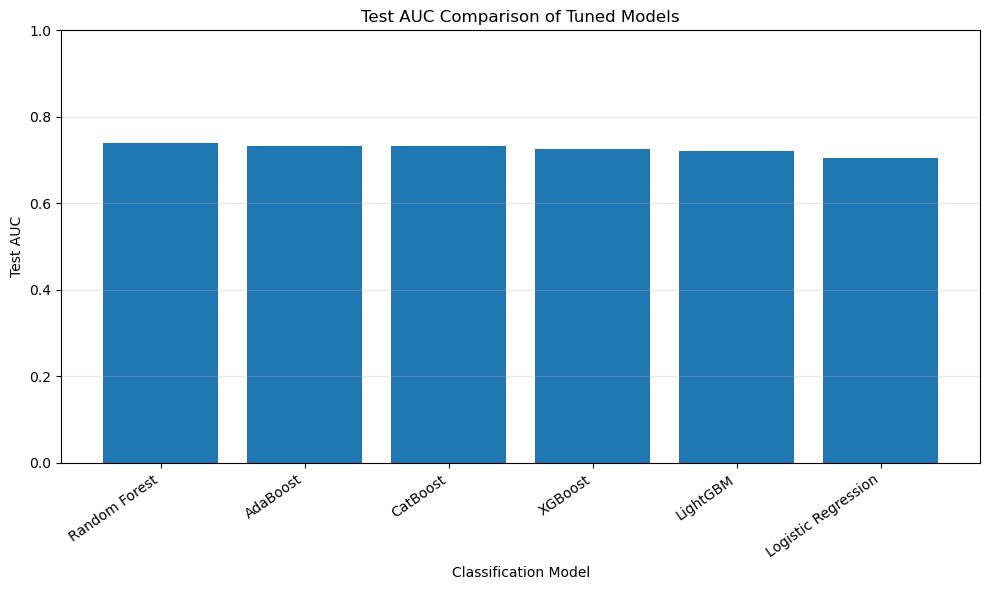

In [55]:
plt.figure(figsize=(10, 6))

plt.bar(
    final_results_df["Model"],
    final_results_df["Test AUC"]
)

plt.xlabel("Classification Model")
plt.ylabel("Test AUC")
plt.title("Test AUC Comparison of Tuned Models")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
